# 05 — Feature Analysis

Feature contributions for feature group **C**, produced only after the evaluation
pipeline has been validated. Interpretations are **predictive, not causal**.

Methods:
- Linear coefficients (with preprocessing context).
- Permutation importance on held-out data for Random Forest and HistGradientBoosting.
- Fold-level permutation-importance stability for HistGradientBoosting.
- Partial dependence for the top features.
- Comparison of RF and HGB importance rankings.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sm_project import config, data, features, modeling, viz

config.ensure_output_dirs()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
print("Project root:", ROOT)
print("Fixed seed:", config.SEED)

Project root: /Users/dhanudriya/Lecturer/ML-project-1
Fixed seed: 42


In [2]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from scipy.stats import spearmanr

df = data.load_data()
analysis = data.eligible_sample(df)
train_idx, test_idx = features.make_split(analysis)
train_df = analysis.iloc[train_idx]
test_df = analysis.iloc[test_idx]
feature_list = features.get_feature_group("C")
print("Group C features:", feature_list)
print("Train:", len(train_df), "| Test:", len(test_df))

Group C features: ['Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Late_Night_Usage', 'Social_Comparison_Frequency', 'Primary_Platform', 'Device_Type', 'Age', 'Gender', 'Academic_Level', 'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index']
Train: 3532 | Test: 883


## 1. Fit the final model families on the training partition

In [3]:
tuned_path = config.TABLES_DIR / "03_tuned_params.json"
tuned_params = modeling.load_json(tuned_path) if tuned_path.exists() else {}
base_models = modeling.default_models()

fitted = {}
for model_name in ["Linear Regression", "Random Forest", "Hist Gradient Boosting"]:
    estimator = base_models[model_name]
    if model_name in tuned_params:
        estimator = estimator.set_params(**tuned_params[model_name])
    pipeline = features.build_pipeline(
        estimator, feature_list, scale_numeric=modeling.needs_scaling(model_name)
    )
    pipeline.fit(train_df[feature_list], train_df[config.TARGET])
    fitted[model_name] = pipeline
    score = pipeline.score(test_df[feature_list], test_df[config.TARGET])
    print(f"{model_name}: held-out R2 = {score:.4f}")

Linear Regression: held-out R2 = 0.5671


Random Forest: held-out R2 = 0.5497


Hist Gradient Boosting: held-out R2 = 0.5463


## 2. Permutation importance on held-out data

,model,feature,importance_mae_increase_mean,importance_mae_increase_std
0,Random Forest,Daily_Usage_Hours,0.0415,0.0023
1,Random Forest,Perceived_Stress_Score,0.0184,0.0016
2,Random Forest,Mental_Health_Index,0.0135,0.0015
3,Random Forest,Sleep_Duration_Hours,0.0087,0.0008
4,Random Forest,Sleep_Quality_Score,0.0040,0.0007
5,Random Forest,Primary_Platform,0.0003,0.0004
6,Random Forest,Social_Comparison_Frequency,0.0002,0.0004
7,Random Forest,Academic_Level,0.0001,0.0003
8,Random Forest,Age,0.0000,0.0002
9,Random Forest,Gender,-0.0000,0.0003


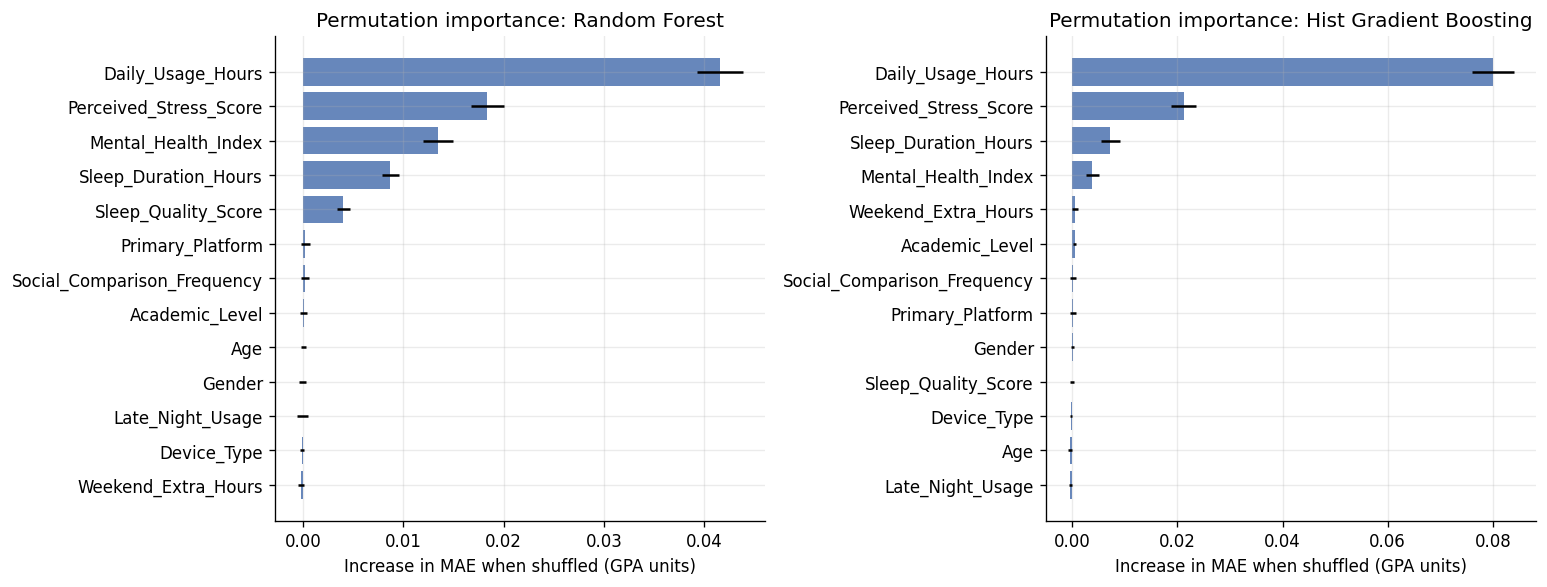

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/05_permutation_importance.png')

In [4]:
importance_frames = []
for model_name in ["Random Forest", "Hist Gradient Boosting"]:
    result = permutation_importance(
        fitted[model_name], test_df[feature_list], test_df[config.TARGET],
        n_repeats=10, random_state=config.SEED, scoring="neg_mean_absolute_error",
    )
    frame = pd.DataFrame(
        {
            "model": model_name,
            "feature": feature_list,
            "importance_mae_increase_mean": result.importances_mean,
            "importance_mae_increase_std": result.importances_std,
        }
    ).sort_values("importance_mae_increase_mean", ascending=False)
    importance_frames.append(frame)

importances = pd.concat(importance_frames, ignore_index=True)
display(importances.round(4))
importances.to_csv(config.TABLES_DIR / "05_permutation_importance.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for ax, model_name in zip(axes, ["Random Forest", "Hist Gradient Boosting"]):
    sub = importances[importances["model"] == model_name].sort_values("importance_mae_increase_mean")
    ax.barh(sub["feature"], sub["importance_mae_increase_mean"],
            xerr=sub["importance_mae_increase_std"], color="#4C72B0", alpha=0.85)
    ax.set_title(f"Permutation importance: {model_name}")
    ax.set_xlabel("Increase in MAE when shuffled (GPA units)")
viz.finish_figure(fig, "05_permutation_importance.png")

## 3. Linear coefficients with preprocessing context

In [5]:
linear_pipeline = fitted["Linear Regression"]
preprocessor = linear_pipeline.named_steps["preprocess"]
model = linear_pipeline.named_steps["model"]
feature_names = preprocessor.get_feature_names_out()
coef_table = pd.DataFrame(
    {"encoded_feature": feature_names, "coefficient": model.coef_}
).sort_values("coefficient", key=np.abs, ascending=False)
display(coef_table.head(20).round(4))
coef_table.to_csv(config.TABLES_DIR / "05_linear_coefficients.csv", index=False)
print("Numeric predictors were standardized; categorical predictors were one-hot encoded.")
print("Coefficients are conditional associations under collinearity, not causal effects.")

,encoded_feature,coefficient
0,num__Daily_Usage_Hours,-0.1704
5,num__Perceived_Stress_Score,-0.0856
3,num__Sleep_Duration_Hours,0.0486
26,cat__Gender_Non-Binary,0.0352
12,cat__Social_Comparison_Frequency_Rarely,-0.0269
24,cat__Gender_Female,-0.0222
11,cat__Social_Comparison_Frequency_Never,0.0197
15,cat__Primary_Platform_LinkedIn,-0.0188
19,cat__Primary_Platform_X (Twitter),-0.0161
17,cat__Primary_Platform_Snapchat,0.0155


Numeric predictors were standardized; categorical predictors were one-hot encoded.
Coefficients are conditional associations under collinearity, not causal effects.


## 4. Fold-level stability of HGB permutation importance

In [6]:
hgb_params = tuned_params.get("Hist Gradient Boosting", {})
from sklearn.ensemble import HistGradientBoostingRegressor

fold_importances = []
for fold, (fit_idx, val_idx) in enumerate(modeling.make_cv().split(train_df), start=1):
    fit_part = train_df.iloc[fit_idx]
    val_part = train_df.iloc[val_idx]
    estimator = HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=31, random_state=config.SEED,
        **{k: v for k, v in hgb_params.items()
           if k not in {"max_iter", "learning_rate", "max_leaf_nodes"}},
    )
    pipeline = features.build_pipeline(estimator, feature_list, scale_numeric=False)
    pipeline.fit(fit_part[feature_list], fit_part[config.TARGET])
    result = permutation_importance(
        pipeline, val_part[feature_list], val_part[config.TARGET],
        n_repeats=5, random_state=config.SEED, scoring="neg_mean_absolute_error",
    )
    fold_importances.append(
        pd.DataFrame(
            {"fold": fold, "feature": feature_list, "importance": result.importances_mean}
        )
    )
fold_importance = pd.concat(fold_importances, ignore_index=True)
stability = (
    fold_importance.groupby("feature")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
display(stability.round(4))
stability.to_csv(config.TABLES_DIR / "05_importance_stability.csv")

,mean,std
feature,,
Daily_Usage_Hours,0.0687,0.0079
Perceived_Stress_Score,0.0156,0.0041
Sleep_Duration_Hours,0.0050,0.0041
Mental_Health_Index,0.0021,0.0020
Primary_Platform,0.0008,0.0009
Social_Comparison_Frequency,0.0004,0.0013
Academic_Level,0.0003,0.0009
Sleep_Quality_Score,-0.0000,0.0006
Device_Type,-0.0001,0.0002


## 5. Partial dependence for top HGB features

Top features: ['Daily_Usage_Hours', 'Perceived_Stress_Score', 'Sleep_Duration_Hours']


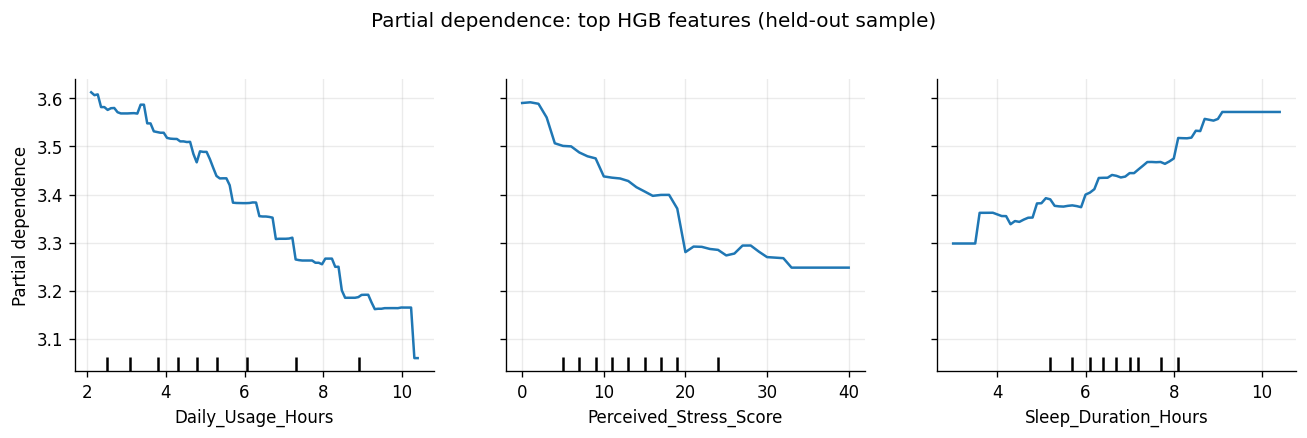

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/05_partial_dependence.png')

In [7]:
top_features = (
    importances[importances["model"] == "Hist Gradient Boosting"]
    .sort_values("importance_mae_increase_mean", ascending=False)
    .head(3)["feature"].tolist()
)
print("Top features:", top_features)
sample = test_df.sample(min(500, len(test_df)), random_state=config.SEED)
fig, ax = plt.subplots(figsize=(11, 3.5))
PartialDependenceDisplay.from_estimator(
    fitted["Hist Gradient Boosting"], sample[feature_list], top_features,
    ax=ax, kind="average",
)
fig.suptitle("Partial dependence: top HGB features (held-out sample)", y=1.03)
viz.finish_figure(fig, "05_partial_dependence.png")

## 6. Cross-model rank consistency

In [8]:
wide = importances.pivot(index="feature", columns="model",
                         values="importance_mae_increase_mean")
rho, p_value = spearmanr(wide["Random Forest"], wide["Hist Gradient Boosting"])
print("Spearman rank correlation between RF and HGB permutation importance:", round(rho, 3))
print("p-value:", round(p_value, 4))
display(wide.round(4).sort_values("Hist Gradient Boosting", ascending=False))
wide.to_csv(config.TABLES_DIR / "05_importance_by_model.csv")

Spearman rank correlation between RF and HGB permutation importance: 0.687
p-value: 0.0095


model,Hist Gradient Boosting,Random Forest
feature,,
Daily_Usage_Hours,0.0800,0.0415
Perceived_Stress_Score,0.0211,0.0184
Sleep_Duration_Hours,0.0072,0.0087
Mental_Health_Index,0.0038,0.0135
Weekend_Extra_Hours,0.0005,-0.0002
Academic_Level,0.0004,0.0001
Primary_Platform,0.0001,0.0003
Social_Comparison_Frequency,0.0001,0.0002
Gender,0.0000,-0.0000


## 7. Summary

In [9]:
rf_top = importances[importances["model"] == "Random Forest"].head(3)["feature"].tolist()
hgb_top = importances[importances["model"] == "Hist Gradient Boosting"].head(3)["feature"].tolist()
report_lines = [
    "# Feature Analysis Summary",
    "",
    f"- Group C features analysed: {len(feature_list)}.",
    f"- Top RF permutation-importance features: {', '.join(rf_top)}.",
    f"- Top HGB permutation-importance features: {', '.join(hgb_top)}.",
    f"- RF vs HGB importance rank correlation (Spearman): {rho:.3f} (p={p_value:.4f}).",
    "",
    "## Caveats",
    "",
    "- Permutation importance measures how much predictive performance changes when a feature "
    "is shuffled; it is not a causal effect.",
    "- Strongly correlated predictors (usage, sleep, stress, mental health) can share or split "
    "importance, and permutation can create unrealistic feature combinations.",
    "- Linear coefficients are conditional on the other included predictors and on scaling; "
    "their signs and magnitudes should not be read causally.",
    "- Results describe this supplied dataset, whose provenance is unverified and whose "
    "generation process may be synthetic.",
]
summary_text = "\n".join(report_lines)
(config.REPORTS_DIR / "05_feature_analysis.md").write_text(summary_text, encoding="utf-8")
display(Markdown(summary_text))

# Feature Analysis Summary

- Group C features analysed: 13.
- Top RF permutation-importance features: Daily_Usage_Hours, Perceived_Stress_Score, Mental_Health_Index.
- Top HGB permutation-importance features: Daily_Usage_Hours, Perceived_Stress_Score, Sleep_Duration_Hours.
- RF vs HGB importance rank correlation (Spearman): 0.687 (p=0.0095).

## Caveats

- Permutation importance measures how much predictive performance changes when a feature is shuffled; it is not a causal effect.
- Strongly correlated predictors (usage, sleep, stress, mental health) can share or split importance, and permutation can create unrealistic feature combinations.
- Linear coefficients are conditional on the other included predictors and on scaling; their signs and magnitudes should not be read causally.
- Results describe this supplied dataset, whose provenance is unverified and whose generation process may be synthetic.